# 01. 화학 언어모델 임베딩 vs ECFP·RDKit 기술자 — 분할을 바꾸면 무엇이 달라지는가?

**등급**: 🟢 Mac 로컬 (CPU) · Colab T4에서도 실행 확인(약 60분, CPU 작업이라 느림) · **예상 시간**: 약 10분 (대부분 분할×표현×head 교차검증과 부트스트랩) · **다운로드**: MoleculeNet CSV 3개 합 약 0.5 MB, ChemBERTa-77M-MLM·MTR 각 약 14 MB(`.bin`), rdkit(pip, 약 26 MB)

**질문**
1. 동결(frozen)된 ChemBERTa-77M 임베딩 + 단순 head가, 같은 head를 쓴 **ECFP4 지문**이나 **RDKit 기술자**를 이기는가?
2. random → scaffold → 유사도 군집 분할로 갈수록 성능이 얼마나 떨어지는가? train과의 **최근접 유사도**로 누출 정도를 직접 측정하면?
3. 사전학습의 기여는 얼마인가? (같은 구조의 **무작위 초기화** 대조군)
4. FM 고유 점검: 층/풀링 선택, SMILES 표기 변형(같은 분자, 다른 문자열)에 대한 민감도, MTR 변형은 무엇을 이미 알고 있는가?

**설계 (결과를 보기 전에 정한 것)**
- 데이터(MoleculeNet): ESOL(용해도 logS, 회귀), Lipophilicity(logD, 회귀), BBBP(혈액-뇌 장벽 투과, 이진분류).
- 표현 6종: ECFP4 count(2048, log1p) · RDKit 기술자 217개 중 상수 열을 뺀 199~211개(부호 있는 log1p) · **RDKit 8개**(MolLogP, MolWt, TPSA, 회전결합, 공여/수용체, 고리 수, Fsp3; 극단적으로 작은 baseline) · ChemBERTa-77M-**MLM**(마지막 층, 특수 토큰 제외 평균) · ChemBERTa-77M-**MTR** · MLM **무작위 초기화**.
- head 2종: **선형**(Ridge/RidgeClassifier, 정규화 세기는 학습 fold 안에서 자동 선택)이 주 지표이고, **랜덤 포레스트**(100 트리)는 민감도다.
- 분할 3종, 각각 5-fold × 3회 반복: random · Bemis–Murcko **scaffold** 묶음 · ECFP4 Tanimoto **Butina 군집** 묶음(거리 컷오프 0.6). 폴드 크기는 균형을 맞춘 그룹 폴드다.
- 사전 지정한 주 비교(선형 head): (a) MLM − ECFP4, (b) MLM − 무작위 초기화. 나머지는 탐색적이다. 신뢰구간은 **Butina 군집 단위 부트스트랩**이다. 분자들이 비슷한 이웃끼리 오차가 상관되므로 군집을 재표본 단위로 쓴다. 이 구간은 이미 계산된 예측에 대한 조건부 구간이며 모델 재학습 변동은 담지 않는다.
- 지표: 회귀는 전체 out-of-fold 예측의 RMSE(낮을수록 좋음), BBBP는 **폴드별 ROC-AUC의 평균**(높을수록 좋음; 폴드마다 다른 모델의 점수 척도를 하나로 섞어 AUC를 구하면 상수 예측도 0.5에서 벗어난다).

> 하이퍼파라미터는 **표현별로 튜닝하지 않았다**(ECFP 반경·비트 수, RF 설정 모두 고정). 어느 쪽도 최적 성능이 아니므로, 결과는 "이 고정 설정에서의 비교"다.

In [1]:
import hashlib
import importlib.metadata as md
import io
import os
import pickletools
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Cluster import Butina
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import RidgeCV, RidgeClassifierCV
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
RDLogger.DisableLog("rdApp.*")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
CACHE = (ROOT / ".cache") if ROOT is not None else Path("cache")
os.environ.setdefault("HF_HOME", str(CACHE / "hf"))
MOL = CACHE / "molecules"
MOL.mkdir(parents=True, exist_ok=True)

import torch
from huggingface_hub import snapshot_download
from transformers import AutoConfig, AutoModel, AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
import rdkit

print("cache:", CACHE)
print({k: md.version(k) for k in ["numpy", "pandas", "scikit-learn", "torch", "transformers"]} | {"rdkit": rdkit.__version__})

cache: <repo>/.cache
{'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'transformers': '5.22.1', 'rdkit': '2026.09.1'}


## 1. 데이터와 모델 내려받기, 체크포인트 점검
- MoleculeNet(Wu et al., *Chem Sci* 2018) CSV를 DeepChem 공개 버킷에서 받는다(파일별 sha256 고정). 데이터별 원 출처: ESOL(Delaney 2004), Lipophilicity(AstraZeneca가 ChEMBL에 올린 자료), BBBP(Martins et al. 2012). **라이선스는 출처별로 확인하지 못했으므로 재배포하지 않고** 로컬 캐시로만 쓴다.
- ChemBERTa-77M-MLM/MTR(DeepChem)은 `pytorch_model.bin`만 있고 **모델 카드가 없다**. 이 체크포인트의 PyTorch `.bin`은 pickle 기반이다. 아래에서 저장소 리비전을 고정해 내려받고, pickle이 참조하는 전역 객체를 훑어본다.
- **출처(provenance) 주의**: `from_pretrained("저장소 ID", revision=...)`으로 `.bin` 전용 저장소를 열면, 이 환경(transformers 5.22.1)에서는 Hub의 *자동 변환 PR 브랜치*(`refs/pr/N`)에서 safetensors를 추가로 받아 쓰는 일이 실제로 있었다(고정한 리비전과 다른 커밋). 그래서 아래에서는 `snapshot_download`로 받은 **로컬 디렉터리 경로**에서만 불러온다.

In [2]:
BASE = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/"
CSV = {
    "esol": ("delaney-processed.csv", "8c06a76f0c6487d29ab0f903e6a7a7139f189ab3c1178f159c8be8964602f189"),
    "lipo": ("Lipophilicity.csv", "aed41590cb30609d51d8e08ad3ff06495a76e80e211358801f596b10da69bacd"),
    "bbbp": ("BBBP.csv", "d07a38487aeac5cee5508413e468043ef3097451d2a112701c2d60be9ec6b662"),
}


def sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()


for key, (fn, digest) in CSV.items():
    p = MOL / fn
    if not p.exists():
        print("downloading", fn)
        urllib.request.urlretrieve(BASE + fn, p.with_suffix(".part"))
        p.with_suffix(".part").rename(p)
    assert sha256(p) == digest, f"{fn}: sha256이 기록된 값과 다르다"
    print(f"{fn:24s} sha256 일치 | {p.stat().st_size / 1e3:.0f} KB")

MODELS = {
    "MLM": ("DeepChem/ChemBERTa-77M-MLM", "ed8a5374f2024ec8da53760af91a33fb8f6a15ff"),
    "MTR": ("DeepChem/ChemBERTa-77M-MTR", "66b895cab8adebea0cb59a8effa66b2020f204ca"),
}
LOCAL = {k: Path(snapshot_download(repo, revision=rev, allow_patterns=["pytorch_model.bin", "*.json", "merges.txt"])) for k, (repo, rev) in MODELS.items()}


def audit_torch_bin(path):
    # 근사 점검(방어 수단이 아니다): pickle의 GLOBAL/STACK_GLOBAL이 가리키는 "모듈 이름"만 모은다
    path = Path(path)
    seen, strs = set(), []

    def scan(stream):
        for op, arg, _ in pickletools.genops(stream):
            if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE"):
                strs.append(arg)
            elif op.name == "GLOBAL":
                seen.add(arg)
            elif op.name == "STACK_GLOBAL":
                seen.add(" ".join(strs[-2:]))

    if zipfile.is_zipfile(path):                       # torch>=1.6 기본 형식
        with zipfile.ZipFile(path) as z:
            scan(io.BytesIO(z.read(next(n for n in z.namelist() if n.endswith("data.pkl")))))
        fmt = "zip"
    else:                                              # 구형 순차 형식: 매직 넘버, 프로토콜, sys_info, 본체 순으로 pickle 4개
        f = io.BytesIO(path.read_bytes())
        for _ in range(4):
            scan(f)
        fmt = "legacy"
    return fmt, sorted(seen)


for k, p in LOCAL.items():
    f = p / "pytorch_model.bin"
    print(f"{k}: 리비전 {p.name[:8]} | {f.stat().st_size / 1e6:.1f} MB | sha256 {sha256(f)[:16]}… | 형식·pickle 전역 참조: {audit_torch_bin(f)}")

delaney-processed.csv    sha256 일치 | 97 KB
Lipophilicity.csv        sha256 일치 | 283 KB
BBBP.csv                 sha256 일치 | 149 KB
MLM: 리비전 ed8a5374 | 13.7 MB | sha256 95571af26b61ba8d… | 형식·pickle 전역 참조: ('legacy', ['collections OrderedDict', 'torch FloatStorage', 'torch LongStorage', 'torch._utils _rebuild_tensor_v2'])
MTR: 리비전 66b895ca | 14.0 MB | sha256 7882205587d3985c… | 형식·pickle 전역 참조: ('legacy', ['collections OrderedDict', 'torch FloatStorage', 'torch LongStorage', 'torch._utils _rebuild_tensor_v2'])


## 2. 데이터 정리: 잘못된 SMILES, 중복, 라벨 충돌, scaffold
- RDKit이 못 읽는 SMILES는 제거한다. 같은 분자(정규화 SMILES가 같음)가 여러 행이면 **한 행으로 합친다**: 회귀는 라벨 평균, 분류는 라벨이 충돌하면 그룹 전체를 버린다. (합치지 않으면 같은 분자가 train과 test에 동시에 들어가는 **직접 누출**이 생긴다.)
- scaffold 그룹: Bemis–Murcko 골격이 같으면 같은 그룹. **고리가 없는 분자(골격이 빈 문자열)는 분자마다 자기만의 그룹**으로 둔다. 빈 골격을 하나의 큰 그룹으로 두면 ESOL에서 분자의 약 28%가 한 폴드에 몰려, 분할이 "고리 없는 분자 전체를 예측하라"는 다른 문제가 되기 때문이다. (DeepChem의 결정적 scaffold 분할은 이 큰 그룹을 train에 넣는다. 우리 분할은 그와 다르다.)

In [3]:
TASKS = {
    "esol": dict(file="delaney-processed.csv", y="measured log solubility in mols per litre", kind="reg", title="ESOL logS"),
    "lipo": dict(file="Lipophilicity.csv", y="exp", kind="reg", title="Lipophilicity logD"),
    "bbbp": dict(file="BBBP.csv", y="p_np", kind="clf", title="BBBP"),
}


def load_task(key):
    cfg = TASKS[key]
    raw = pd.read_csv(MOL / cfg["file"])
    raw["can"] = [Chem.MolToSmiles(m) if (m := Chem.MolFromSmiles(s)) is not None else None for s in raw["smiles"]]
    n_invalid = int(raw["can"].isna().sum())
    d = raw.dropna(subset=["can"])[["can", cfg["y"]]].rename(columns={cfg["y"]: "y"})
    g = d.groupby("can", sort=False)["y"]
    spread = g.agg(lambda s: s.max() - s.min())
    n_dup_groups = int((g.size() > 1).sum())
    n_conflict = int((spread > 0).sum())
    if cfg["kind"] == "reg":
        out = g.mean().reset_index()
    else:
        out = g.first()[spread == 0].reset_index()
    mols = [Chem.MolFromSmiles(s) for s in out["can"]]
    scaf = [MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols]
    group = np.array([s if s != "" else f"acyclic_{i}" for i, s in enumerate(scaf)])
    stats = dict(raw=len(raw), invalid=n_invalid, dup_groups=n_dup_groups, conflicting=n_conflict, final=len(out),
                 acyclic=int((np.array(scaf) == "").sum()))
    return dict(df=out, mols=mols, group=group, y=out["y"].values.astype(float), kind=cfg["kind"], stats=stats)


DATA = {k: load_task(k) for k in TASKS}
rows = []
for k, d in DATA.items():
    vc = pd.Series(d["group"]).value_counts()
    rows.append(dict(task=TASKS[k]["title"], **d["stats"], scaffold_groups=len(vc), singleton_groups=int((vc == 1).sum()),
                     largest_group=int(vc.iloc[0]), y=(f"{d['y'].mean():.2f}±{d['y'].std():.2f}" if d["kind"] == "reg" else f"양성 {d['y'].mean():.2f}")))
print(pd.DataFrame(rows).set_index("task").to_string())

                     raw  invalid  dup_groups  conflicting  final  acyclic  scaffold_groups  singleton_groups  largest_group           y
task                                                                                                                                    
ESOL logS           1128        0          11            6   1117      316              584               513            253  -3.05±2.09
Lipophilicity logD  4200        0           0            0   4200        5             2412              1862             76   2.19±1.20
BBBP                2050       11          60           10   1965       95             1114               872            128     양성 0.76


## 3. 분할과 누출 측정
- `random`: 분자 단위 5-fold. `scaffold`: 같은 Bemis–Murcko 골격은 같은 폴드. `cluster`: ECFP4(2048비트) Tanimoto 유사도 ≥ 0.4인 이웃을 묶는 Butina 군집을 같은 폴드로.
- 폴드는 크기를 맞춘 그룹 폴드(큰 그룹부터 가장 작은 폴드에 배정, 동률은 무작위). 3회 반복은 시드만 다르다.
- **누출 지표**: test 분자마다 train 분자 중 가장 비슷한 것과의 Tanimoto 유사도. 분할이 실제로 "새로운 화학"을 만드는지 숫자로 본다. (scaffold 분할은 골격만 다를 뿐 비슷한 분자가 남는다는 지적: Guo et al. 2024.)

In [4]:
FPGEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
K, R = 5, 3


def balanced_group_folds(groups, k, seed):
    rng = np.random.default_rng(seed)
    u, inv = np.unique(groups, return_inverse=True)
    sizes = np.bincount(inv)
    order = np.lexsort((rng.random(len(u)), -sizes))
    load, assign = np.zeros(k), np.zeros(len(u), int)
    for g in order:
        f = int(np.argmin(load))
        assign[g] = f
        load[f] += sizes[g]
    fo = assign[inv]
    return [(np.where(fo != f)[0], np.where(fo == f)[0]) for f in range(k)]


def butina_ids(fps, sim_thr=0.4):
    n = len(fps)
    dists = []
    for i in range(1, n):
        dists.extend((1.0 - np.asarray(DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i]))).tolist())
    clusters = Butina.ClusterData(dists, n, 1.0 - sim_thr, isDistData=True)
    ids = np.zeros(n, int)
    for c, members in enumerate(clusters):
        ids[list(members)] = c
    return ids


t0 = time.time()
FPS, GROUPS, FOLDS = {}, {}, {}
for k, d in DATA.items():
    FPS[k] = [FPGEN.GetFingerprint(m) for m in d["mols"]]
    GROUPS[k] = {"random": np.arange(len(d["y"])), "scaffold": d["group"], "cluster": butina_ids(FPS[k])}
    FOLDS[k] = {}
    for sp, grp in GROUPS[k].items():
        if sp == "random":
            FOLDS[k][sp] = [list(KFold(K, shuffle=True, random_state=r).split(np.arange(len(grp)))) for r in range(R)]
        else:
            FOLDS[k][sp] = [balanced_group_folds(grp, K, r) for r in range(R)]
print("분할 준비: %.0f초" % (time.time() - t0))
print(pd.DataFrame({TASKS[k]["title"]: {sp: f"{len(np.unique(g))}군집/그룹" for sp, g in GROUPS[k].items()} for k in DATA}).T.to_string())

분할 준비: 3초
                       random   scaffold    cluster
ESOL logS           1117군집/그룹   584군집/그룹   420군집/그룹
Lipophilicity logD  4200군집/그룹  2412군집/그룹  1269군집/그룹
BBBP                1965군집/그룹  1114군집/그룹   792군집/그룹


누출 측정: 9초
              task    split  nn_sim_median  nn_sim_p10  frac_ge_0p7  frac_ge_0p5          fold_sizes
         ESOL logS   random           0.55        0.31         0.21         0.66 224/224/223/223/223
         ESOL logS scaffold           0.47        0.28         0.11         0.44 253/216/216/216/216
         ESOL logS  cluster           0.42        0.27         0.05         0.36 224/224/223/223/223
Lipophilicity logD   random           0.70        0.33         0.49         0.73 840/840/840/840/840
Lipophilicity logD scaffold           0.57        0.31         0.26         0.61 840/840/840/840/840
Lipophilicity logD  cluster           0.37        0.28         0.05         0.21 840/840/840/840/840
              BBBP   random           0.57        0.29         0.29         0.62 393/393/393/393/393
              BBBP scaffold           0.46        0.27         0.09         0.43 393/393/393/393/393
              BBBP  cluster           0.37        0.25         0.05         0.22 

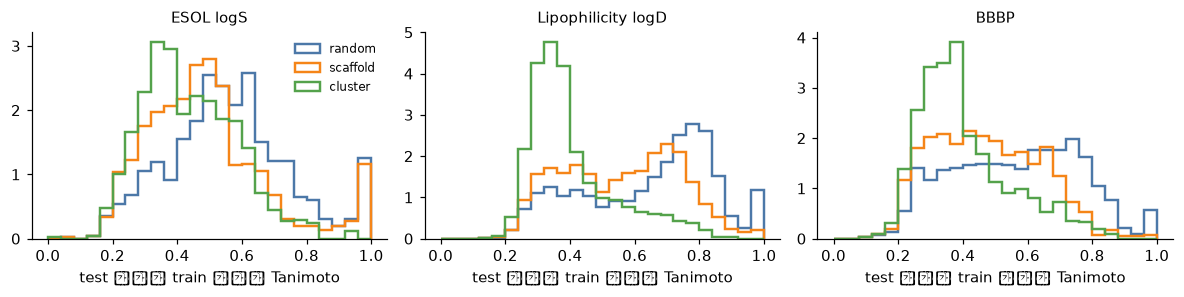

In [5]:
def nearest_train_sim(k, folds):
    sims = []
    for tr, te in folds:
        trf = [FPS[k][j] for j in tr]
        sims += [max(DataStructs.BulkTanimotoSimilarity(FPS[k][i], trf)) for i in te]
    return np.array(sims)


t0 = time.time()
NN = {(k, sp): nearest_train_sim(k, FOLDS[k][sp][0]) for k in DATA for sp in ["random", "scaffold", "cluster"]}
print("누출 측정: %.0f초" % (time.time() - t0))
rows = []
for (k, sp), v in NN.items():
    rows.append(dict(task=TASKS[k]["title"], split=sp, nn_sim_median=np.median(v), nn_sim_p10=np.percentile(v, 10), frac_ge_0p7=np.mean(v >= 0.7), frac_ge_0p5=np.mean(v >= 0.5),
                     fold_sizes="/".join(str(len(te)) for _, te in FOLDS[k][sp][0])))
print(pd.DataFrame(rows).round(2).to_string(index=False))
fig, axs = plt.subplots(1, 3, figsize=(11, 2.8), sharey=False)
for ax, k in zip(axs, DATA):
    for sp, c in zip(["random", "scaffold", "cluster"], ["#4c78a8", "#f58518", "#54a24b"]):
        ax.hist(NN[(k, sp)], bins=np.linspace(0, 1, 26), histtype="step", lw=1.6, color=c, label=sp, density=True)
    ax.set_title(TASKS[k]["title"], fontsize=10)
    ax.set_xlabel("test 분자의 train 최근접 Tanimoto")
axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 4. 표현 만들기
- **ECFP4**: 반지름 2, 2048칸 count 지문 → `log1p`.
- **RDKit 기술자**: `Descriptors.CalcMolDescriptors` 전체(217개). 모든 분자에서 값이 같은 열은 예측에 영향이 없어 빼므로 데이터마다 199~211개가 남는다. 값의 범위가 극단적이므로 모든 열에 `sign(x)·log1p(|x|)`를 적용한 뒤 학습 fold에서 표준화한다. **RDKit 8개**는 해석 가능한 최소 baseline이다.
- **ChemBERTa-77M**: 3층, 은닉 384, 어휘 600의 RoBERTa형 모델(약 330만 매개변수; "77M"은 사전학습에 쓴 PubChem 분자 수). 임베딩 = 마지막 층 은닉 상태를 `<s>`·`</s>`·패딩을 제외하고 평균. `AutoModel`의 `pooler_output`은 체크포인트에 없어 **무작위로 초기화**되므로 쓰지 않는다(`add_pooling_layer=False`).
- **무작위 초기화**: 같은 설정으로 가중치만 무작위(시드 0). 사전학습이 준 것을 분리하는 대조군이다.

In [6]:
RD8 = ["MolLogP", "MolWt", "TPSA", "NumRotatableBonds", "NumHDonors", "NumHAcceptors", "RingCount", "FractionCSP3"]


def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def rdkit_features(mols):
    rows = [Descriptors.CalcMolDescriptors(m) for m in mols]
    df = pd.DataFrame(rows)
    return df


@torch.no_grad()
def chemberta_layers(model_key, smiles, random_init=False, batch=128):
    """모든 층(0=임베딩 출력 … 3)의 평균 풀링과 <s> 토큰 상태를 반환: dict(mean=[L+1,n,d], cls=[L+1,n,d])."""
    p = LOCAL[model_key]
    tok = AutoTokenizer.from_pretrained(p)
    if random_init:
        torch.manual_seed(SEED)
        model = AutoModel.from_config(AutoConfig.from_pretrained(p), add_pooling_layer=False)
    else:
        model = AutoModel.from_pretrained(p, add_pooling_layer=False)
    model.eval()
    order = np.argsort([len(s) for s in smiles])
    mean = cls = None
    n_trunc = 0
    for s in range(0, len(smiles), batch):
        ix = order[s:s + batch]
        b = tok([smiles[i] for i in ix], return_tensors="pt", padding=True, truncation=True, max_length=512)
        n_trunc += int((b["attention_mask"].sum(1) >= 512).sum())
        hs = torch.stack(model(**b, output_hidden_states=True).hidden_states)       # [L+1, B, T, d]
        am = b["attention_mask"].clone()
        last = am.sum(1) - 1
        am[:, 0] = 0
        am[torch.arange(len(ix)), last] = 0
        w = am[None, :, :, None].float()
        m_ = (hs * w).sum(2) / w.sum(2).clamp(min=1)
        c_ = hs[:, :, 0, :]
        if mean is None:
            mean, cls = (np.zeros((hs.shape[0], len(smiles), hs.shape[-1]), np.float32) for _ in range(2))
        mean[:, ix], cls[:, ix] = m_.numpy(), c_.numpy()
    return dict(mean=mean, cls=cls, n_trunc=n_trunc)


# 자체 점검: 한 분자를 혼자 넣은 결과 == 패딩된 배치 안의 결과
test_smiles = ["CCO", "c1ccccc1O", "CC(=O)Oc1ccccc1C(=O)O", "CCN(CC)CC"]
a = chemberta_layers("MLM", test_smiles)["mean"][-1]
b = np.stack([chemberta_layers("MLM", [s])["mean"][-1][0] for s in test_smiles])
print("단독 vs 배치 최대 절대차: %.2e (임베딩 크기 중앙값 %.2f)" % (np.abs(a - b).max(), np.median(np.abs(a))))

W1110 12:28:15.497000 34633 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


단독 vs 배치 최대 절대차: 4.77e-07 (임베딩 크기 중앙값 0.13)


In [7]:
t0 = time.time()
REPS, LAYERS = {}, {}
for k, d in DATA.items():
    smi = d["df"]["can"].tolist()
    X = {}
    X["ECFP4"] = np.log1p(np.stack([FPGEN.GetCountFingerprintAsNumPy(m) for m in d["mols"]]).astype(np.float32))
    desc = rdkit_features(d["mols"])
    X["RDKit-8"] = np.nan_to_num(desc[RD8].values.astype(np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    full = desc.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    full = full.loc[:, full.std() > 0]
    X["RDKit-217"] = signed_log1p(np.clip(full.values.astype(np.float64), -1e12, 1e12))
    L = {}
    for mk in ["MLM", "MTR"]:
        L[mk] = chemberta_layers(mk, smi)
    L["MLM-rand"] = chemberta_layers("MLM", smi, random_init=True)
    X["ChemBERTa-MLM"], X["ChemBERTa-MTR"], X["MLM-random-init"] = (L[m]["mean"][-1] for m in ["MLM", "MTR", "MLM-rand"])
    REPS[k], LAYERS[k] = X, L
    print(f"{TASKS[k]['title']:20s} n={len(smi)} | " + ", ".join(f"{n}:{v.shape[1]}" for n, v in X.items()) + f" | 512토큰 초과 {L['MLM']['n_trunc']}개")
print("표현 계산: %.0f초" % (time.time() - t0))

ESOL logS            n=1117 | ECFP4:2048, RDKit-8:8, RDKit-217:199, ChemBERTa-MLM:384, ChemBERTa-MTR:384, MLM-random-init:384 | 512토큰 초과 0개


Lipophilicity logD   n=4200 | ECFP4:2048, RDKit-8:8, RDKit-217:208, ChemBERTa-MLM:384, ChemBERTa-MTR:384, MLM-random-init:384 | 512토큰 초과 0개


BBBP                 n=1965 | ECFP4:2048, RDKit-8:8, RDKit-217:211, ChemBERTa-MLM:384, ChemBERTa-MTR:384, MLM-random-init:384 | 512토큰 초과 0개
표현 계산: 53초


## 5. 평가: 분할 × 표현 × head
- 선형 head: 회귀는 `RidgeCV`(내부 leave-one-out으로 α 선택), 분류는 `RidgeClassifierCV`(결정 함수로 ROC-AUC). ECFP는 그대로, 나머지는 학습 fold에서 `StandardScaler`를 적합해 변환한다.
- 비선형 head: `RandomForest`(100 트리, `max_features="sqrt"`).
- 각 (과제, 분할, 표현, head)에서 3회 반복의 out-of-fold 예측을 저장한다.

In [8]:
ALPHAS = np.logspace(-2, 5, 15)
SPLITS = ["random", "scaffold", "cluster"]
REP_NAMES = ["ECFP4", "RDKit-217", "RDKit-8", "ChemBERTa-MLM", "ChemBERTa-MTR", "MLM-random-init"]


def make_model(rep, head, kind):
    if head == "linear":
        core = RidgeCV(alphas=ALPHAS) if kind == "reg" else RidgeClassifierCV(alphas=ALPHAS)
        return core if rep == "ECFP4" else make_pipeline(StandardScaler(), core)
    cls = RandomForestRegressor if kind == "reg" else RandomForestClassifier
    return cls(n_estimators=100, max_features="sqrt", n_jobs=-1, random_state=SEED)


def predict(model, X, kind):
    if kind == "reg":
        return model.predict(X)
    return model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)[:, 1]


def run_cv(Xr, y, folds_r, rep, head, kind):
    out = np.zeros((len(folds_r), len(y)))
    for r, folds in enumerate(folds_r):
        for tr, te in folds:
            out[r, te] = predict(make_model(rep, head, kind).fit(Xr[tr], y[tr]), Xr[te], kind)
    return out


OOF = {}
t0 = time.time()
for k, d in DATA.items():
    for sp in SPLITS:
        for rep in REP_NAMES:
            for head in ["linear", "rf"]:
                OOF[(k, sp, rep, head)] = run_cv(REPS[k][rep], d["y"], FOLDS[k][sp], rep, head, d["kind"])
    print(f"{TASKS[k]['title']} 완료 (누적 {time.time() - t0:.0f}초)", flush=True)

ESOL logS 완료 (누적 36초)


Lipophilicity logD 완료 (누적 283초)


BBBP 완료 (누적 357초)


### 결과 표
구간은 **Butina 군집 단위 부트스트랩**(B=300; 같은 재표본을 모든 표현에 공유)의 2.5–97.5% 분위수, 3회 반복의 지표를 평균한 값이다. `Δ`는 같은 재표본에서 계산한 ECFP4와의 **짝지은 차이**. RMSE는 음수 Δ, ROC-AUC는 양수 Δ가 ECFP4보다 낫다는 뜻이다. BBBP의 AUC는 폴드별로 구해 평균한다(재표본에서도 폴드마다 따로 계산).

In [9]:
B = 300
FOLD_ID = {}          # (과제, 분할) -> [R, n]: 각 분자가 속한 test 폴드 번호
for k in DATA:
    for sp in SPLITS:
        arr = np.zeros((R, len(DATA[k]["y"])), int)
        for r_, folds_ in enumerate(FOLDS[k][sp]):
            for f_, (_, te_) in enumerate(folds_):
                arr[r_, te_] = f_
        FOLD_ID[(k, sp)] = arr


def fold_metric(kind, y, p, fold_id, w=None):
    """회귀: 전체 OOF 예측의 RMSE. 분류: 폴드별 ROC-AUC의 평균."""
    if kind == "reg":
        return float(np.sqrt(np.average((p - y) ** 2, weights=w)))
    aucs = []
    for f in np.unique(fold_id):
        m = fold_id == f
        try:
            aucs.append(roc_auc_score(y[m], p[m], sample_weight=None if w is None else w[m]))
        except ValueError:                               # 재표본에서 한 클래스의 가중치가 모두 0이면 정의되지 않는다
            pass
    return float(np.mean(aucs))


def point_metric(k, sp, oof):
    return float(np.mean([fold_metric(DATA[k]["kind"], DATA[k]["y"], o, FOLD_ID[(k, sp)][r_]) for r_, o in enumerate(oof)]))


def boot_weights(group, B, seed=123):
    rng = np.random.default_rng(seed)
    u, inv = np.unique(group, return_inverse=True)
    draws = rng.integers(0, len(u), (B, len(u)))
    return np.stack([np.bincount(dr, minlength=len(u))[inv] for dr in draws]).astype(float)       # [B, n]


W_BOOT = {k: boot_weights(GROUPS[k]["cluster"], B) for k in DATA}        # 재표본 단위 = Butina 군집 (모든 분할 공통)
_BOOT = {}


def boot_metric(k, sp, rep, head):
    """(과제, 분할, 표현, head)의 부트스트랩 분포 [B] (3회 반복 평균)."""
    key = (k, sp, rep, head)
    if key not in _BOOT:
        d, W, oof = DATA[k], W_BOOT[k], OOF[key]
        if d["kind"] == "reg":
            se = (oof - d["y"][None]) ** 2                                                            # [R, n]
            _BOOT[key] = np.sqrt((W @ se.T) / W.sum(1, keepdims=True)).mean(1)
        else:
            _BOOT[key] = np.array([np.mean([fold_metric("clf", d["y"], o, FOLD_ID[(k, sp)][r_], w) for r_, o in enumerate(oof)]) for w in W])
    return _BOOT[key]


def summarize(k, sp, head):
    base_b = boot_metric(k, sp, "ECFP4", head)
    base_p = point_metric(k, sp, OOF[(k, sp, "ECFP4", head)])
    rows = []
    for rep in REP_NAMES:
        bm = boot_metric(k, sp, rep, head)
        point = point_metric(k, sp, OOF[(k, sp, rep, head)])
        lo, hi = np.percentile(bm, [2.5, 97.5])
        dl, dh = np.percentile(bm - base_b, [2.5, 97.5])
        rows.append(dict(표현=rep, 지표=f"{point:.3f} [{lo:.3f}, {hi:.3f}]",
                         Δ_vs_ECFP4="—" if rep == "ECFP4" else f"{point - base_p:+.3f} [{dl:+.3f}, {dh:+.3f}]"))
    return pd.DataFrame(rows).set_index("표현")


SUMMARY = {}
t0 = time.time()
for k in DATA:
    metric_name = "RMSE↓" if DATA[k]["kind"] == "reg" else "ROC-AUC↑(폴드 평균)"
    for head in ["linear", "rf"]:
        for sp in SPLITS:
            SUMMARY[(k, head, sp)] = summarize(k, sp, head)
    print(f"\n===== {TASKS[k]['title']} · {metric_name} · 선형 head =====")
    print(pd.concat({sp: SUMMARY[(k, "linear", sp)] for sp in SPLITS}, axis=1).to_string())
print("\n부트스트랩: %.0f초" % (time.time() - t0))


===== ESOL logS · RMSE↓ · 선형 head =====
                               random                                       scaffold                                        cluster                         
                                   지표               Δ_vs_ECFP4                    지표               Δ_vs_ECFP4                    지표               Δ_vs_ECFP4
표현                                                                                                                                                          
ECFP4            0.873 [0.826, 0.929]                        —  1.070 [0.990, 1.160]                        —  1.020 [0.931, 1.116]                        —
RDKit-217        0.634 [0.589, 0.679]  -0.239 [-0.293, -0.190]  0.719 [0.672, 0.764]  -0.350 [-0.423, -0.281]  0.672 [0.625, 0.714]  -0.349 [-0.439, -0.263]
RDKit-8          0.983 [0.919, 1.047]  +0.110 [+0.045, +0.168]  1.025 [0.963, 1.090]  -0.044 [-0.134, +0.036]  1.016 [0.937, 1.093]  -0.004 [-0.091, +0.092]
ChemBERTa-MLM    


===== BBBP · ROC-AUC↑(폴드 평균) · 선형 head =====
                               random                                       scaffold                                        cluster                         
                                   지표               Δ_vs_ECFP4                    지표               Δ_vs_ECFP4                    지표               Δ_vs_ECFP4
표현                                                                                                                                                          
ECFP4            0.920 [0.894, 0.938]                        —  0.897 [0.859, 0.920]                        —  0.868 [0.823, 0.894]                        —
RDKit-217        0.896 [0.864, 0.919]  -0.024 [-0.040, -0.010]  0.882 [0.842, 0.907]  -0.014 [-0.034, +0.002]  0.870 [0.826, 0.895]  +0.003 [-0.018, +0.024]
RDKit-8          0.843 [0.794, 0.879]  -0.077 [-0.113, -0.048]  0.841 [0.794, 0.875]  -0.056 [-0.088, -0.028]  0.838 [0.786, 0.870]  -0.029 [-0.063, +0.004]
ChemBERTa-ML

In [10]:
for k in DATA:
    metric_name = "RMSE↓" if DATA[k]["kind"] == "reg" else "ROC-AUC↑(폴드 평균)"
    print(f"\n===== {TASKS[k]['title']} · {metric_name} · 랜덤 포레스트 head (민감도) =====")
    print(pd.concat({sp: SUMMARY[(k, "rf", sp)] for sp in SPLITS}, axis=1).to_string())


===== ESOL logS · RMSE↓ · 랜덤 포레스트 head (민감도) =====
                               random                                       scaffold                                        cluster                         
                                   지표               Δ_vs_ECFP4                    지표               Δ_vs_ECFP4                    지표               Δ_vs_ECFP4
표현                                                                                                                                                          
ECFP4            0.975 [0.913, 1.045]                        —  1.262 [1.111, 1.432]                        —  1.272 [1.102, 1.409]                        —
RDKit-217        0.659 [0.605, 0.718]  -0.316 [-0.379, -0.260]  0.812 [0.728, 0.889]  -0.450 [-0.576, -0.332]  0.772 [0.694, 0.855]  -0.500 [-0.610, -0.373]
RDKit-8          0.665 [0.619, 0.718]  -0.310 [-0.373, -0.258]  0.792 [0.726, 0.865]  -0.470 [-0.609, -0.333]  0.757 [0.688, 0.825]  -0.514 [-0.619, -0.398]
ChemBE

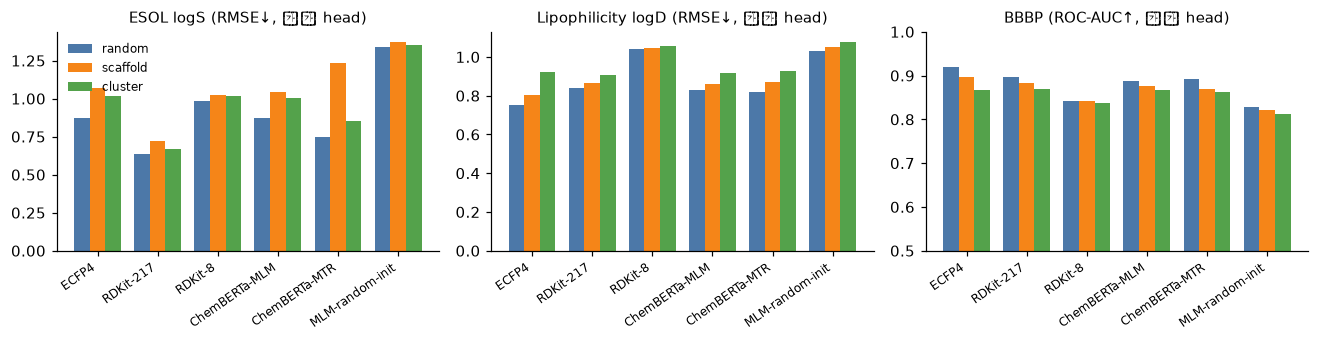

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
w = 0.26
for ax, k in zip(axs, DATA):
    for j, (sp, c) in enumerate(zip(SPLITS, ["#4c78a8", "#f58518", "#54a24b"])):
        vals = [point_metric(k, sp, OOF[(k, sp, rep, "linear")]) for rep in REP_NAMES]
        ax.bar(np.arange(len(REP_NAMES)) + (j - 1) * w, vals, w, color=c, label=sp)
    ax.set_xticks(np.arange(len(REP_NAMES)))
    ax.set_xticklabels(REP_NAMES, rotation=35, ha="right", fontsize=8)
    ax.set_title(f"{TASKS[k]['title']} ({'RMSE↓' if DATA[k]['kind'] == 'reg' else 'ROC-AUC↑'}, 선형 head)", fontsize=10)
    if DATA[k]["kind"] == "clf":
        ax.set_ylim(0.5, 1.0)
axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 6. 주 비교 요약 (사전 지정)
선형 head에서 (a) ChemBERTa-MLM − ECFP4, (b) ChemBERTa-MLM − 무작위 초기화. 짝지은 차이와 그룹 부트스트랩 구간. 구간이 0을 포함하면 "차이가 있다"고 주장하지 않는다.

In [12]:
def paired(k, sp, head, rep_a, rep_b):
    a, b = boot_metric(k, sp, rep_a, head), boot_metric(k, sp, rep_b, head)
    pa = point_metric(k, sp, OOF[(k, sp, rep_a, head)])
    pb = point_metric(k, sp, OOF[(k, sp, rep_b, head)])
    lo, hi = np.percentile(a - b, [2.5, 97.5])
    return f"{pa - pb:+.3f} [{lo:+.3f}, {hi:+.3f}]"


rows = []
for k in DATA:
    for sp in SPLITS:
        rows.append({"과제": TASKS[k]["title"], "분할": sp,
                     "(a) MLM − ECFP4": paired(k, sp, "linear", "ChemBERTa-MLM", "ECFP4"),
                     "(b) MLM − 무작위 초기화": paired(k, sp, "linear", "ChemBERTa-MLM", "MLM-random-init")})
print(pd.DataFrame(rows).to_string(index=False))
print("\n(RMSE: 음수가 MLM이 낫다 / ROC-AUC: 양수가 MLM이 낫다)")

                과제       분할         (a) MLM − ECFP4       (b) MLM − 무작위 초기화
         ESOL logS   random +0.001 [-0.050, +0.063] -0.465 [-0.936, -0.147]
         ESOL logS scaffold -0.025 [-0.094, +0.049] -0.327 [-0.671, -0.088]
         ESOL logS  cluster -0.019 [-0.113, +0.079] -0.352 [-0.752, -0.070]
Lipophilicity logD   random +0.079 [+0.055, +0.102] -0.204 [-0.245, -0.169]
Lipophilicity logD scaffold +0.054 [+0.027, +0.080] -0.189 [-0.233, -0.153]
Lipophilicity logD  cluster -0.007 [-0.054, +0.047] -0.161 [-0.210, -0.114]
              BBBP   random -0.032 [-0.049, -0.017] +0.060 [+0.032, +0.092]
              BBBP scaffold -0.020 [-0.040, -0.002] +0.056 [+0.029, +0.087]
              BBBP  cluster -0.001 [-0.022, +0.020] +0.055 [+0.023, +0.092]

(RMSE: 음수가 MLM이 낫다 / ROC-AUC: 양수가 MLM이 낫다)


### 점검: ESOL 선형 head는 왜 흔들리는가
ESOL의 일부 표현(MTR, 무작위 초기화)은 선형 head에서 구간이 매우 넓다. 원인을 단정하지 않고 **무엇이 일어나는지만** 본다: scaffold 분할·반복 0에서 표현별 최대 절대오차, 오차가 4(로그 단위)를 넘는 예측 수, 폴드별로 선택된 정규화 세기 α, 그리고 MTR에서 오차가 가장 큰 분자 3개.

In [13]:
k, sp = "esol", "scaffold"
d = DATA[k]
rows, worst_mtr = [], None
for rep in ["ECFP4", "ChemBERTa-MLM", "ChemBERTa-MTR", "MLM-random-init"]:
    oof = OOF[(k, sp, rep, "linear")][0]
    err = np.abs(oof - d["y"])
    alphas = []
    for tr, te in FOLDS[k][sp][0]:
        m = make_model(rep, "linear", d["kind"]).fit(REPS[k][rep][tr], d["y"][tr])
        alphas.append((m[-1] if hasattr(m, "steps") else m).alpha_)
    rows.append(dict(표현=rep, RMSE=np.sqrt((err ** 2).mean()), 최대오차=err.max(), 오차4초과=int((err > 4).sum()), 폴드별_alpha=", ".join(f"{a:.3g}" for a in alphas)))
    if rep == "ChemBERTa-MTR":
        worst_mtr = [(d["df"]["can"].iloc[i], d["y"][i], oof[i]) for i in np.argsort(-err)[:3]]
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nMTR에서 오차가 가장 큰 분자 3개 (SMILES, 실제, 예측):")
for smi, yy, pp in worst_mtr:
    print(f"  {smi[:60]:60s} {yy:+.2f} {pp:+.2f}")

             표현  RMSE   최대오차  오차4초과                    폴드별_alpha
          ECFP4 1.049  4.828      1 3.16, 3.16, 3.16, 3.16, 3.16
  ChemBERTa-MLM 1.052  5.189      2 31.6, 31.6, 31.6, 31.6, 31.6
  ChemBERTa-MTR 1.250 14.569      6 31.6, 31.6, 31.6, 31.6, 31.6
MLM-random-init 1.354 21.824      6   0.316, 316, 3.16, 316, 0.1

MTR에서 오차가 가장 큰 분자 3개 (SMILES, 실제, 예측):
  O=C1Nc2ccc(Cl)cc2C(c2ccccc2Cl)=NC1O                          -3.60 -18.17
  CN1C(=O)CN=C(c2ccccc2)c2cc(Cl)ccc21                          -3.75 -17.11
  CN1C(=O)CN=C(c2ccccc2)c2cc([N+](=O)[O-])ccc21                -3.80 -16.83


## 7. FM 고유 점검 ①: 층과 풀링 선택에 얼마나 민감한가
MLM·MTR의 층 0(임베딩 출력)~3, 평균 풀링 vs `<s>` 토큰. scaffold 분할·선형 head·3회 반복 평균. **이 표로 층을 골라 주 결과를 바꾸지 않는다**(test 지표로 고르면 안 된다). 민감도 확인용이다.

In [14]:
def eval_matrix(k, X, sp="scaffold", rep="ChemBERTa-MLM"):
    d = DATA[k]
    o = run_cv(X, d["y"], FOLDS[k][sp], rep, "linear", d["kind"])
    return float(np.mean([fold_metric(d["kind"], d["y"], oo, FOLD_ID[(k, sp)][r_]) for r_, oo in enumerate(o)]))


rows = []
for k in DATA:
    for mk in ["MLM", "MTR"]:
        for layer in range(4):
            for pool in ["mean", "cls"]:
                rows.append(dict(과제=TASKS[k]["title"], 모델=mk, 층=layer, 풀링=pool, 지표=eval_matrix(k, LAYERS[k][mk][pool][layer])))
tab = pd.DataFrame(rows).pivot_table(index=["과제", "모델", "층"], columns="풀링", values="지표").round(3)
print(tab.to_string())

풀링                          cls   mean
과제                 모델  층              
BBBP               MLM 0  0.500  0.828
                       1  0.808  0.869
                       2  0.802  0.862
                       3  0.849  0.877
                   MTR 0  0.500  0.830
                       1  0.851  0.868
                       2  0.869  0.878
                       3  0.887  0.870
ESOL logS          MLM 0  2.110  1.179
                       1  1.275  1.002
                       2  1.257  0.972
                       3  1.386  1.044
                   MTR 0  2.110  1.159
                       1  0.941  0.994
                       2  0.827  0.856
                       3  0.924  1.232
Lipophilicity logD MLM 0  1.204  1.065
                       1  1.082  0.905
                       2  1.072  0.867
                       3  1.000  0.860
                   MTR 0  1.204  1.063
                       1  1.034  0.873
                       2  0.830  0.805
                       3 

## 8. FM 고유 점검 ②: 같은 분자, 다른 문자열
한 분자는 여러 SMILES로 쓸 수 있다(RDKit `MolToRandomSmilesVect`로 무작위 표기를 만든다). ECFP는 분자 그래프에서 계산하므로 표기와 무관하다. 문자열을 읽는 언어모델은 어떤가?
(a) 같은 분자의 정규화 표기 vs 무작위 표기 임베딩의 코사인 유사도를, 서로 **다른** 분자 쌍의 유사도와 비교. (b) **정규화 표기로 학습**한 head에 test 분자를 **무작위 표기**로 넣으면 성능이 얼마나 변하는가 (scaffold 분할, 선형 head, 반복 0만).

In [15]:
def random_smiles(mols, seed=SEED):
    out = []
    for i, m in enumerate(mols):
        s = Chem.MolToRandomSmilesVect(m, 1, randomSeed=seed + i)[0]
        assert Chem.CanonSmiles(s) == Chem.MolToSmiles(m), "무작위 SMILES가 같은 분자가 아니다"
        out.append(s)
    return out


def cos_rows(a, b):
    return (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))


rng = np.random.default_rng(0)
rows = []
for k in ["lipo"]:
    d = DATA[k]
    rs = random_smiles(d["mols"])
    same_str = np.mean([a == b for a, b in zip(rs, d["df"]["can"])])
    for mk in ["MLM", "MTR"]:
        Ec = LAYERS[k][mk]["mean"][-1]
        Er = chemberta_layers(mk, rs)["mean"][-1]
        perm = rng.permutation(len(Ec))
        rows.append(dict(모델=mk, 같은분자_정규화vs무작위_코사인=np.median(cos_rows(Ec, Er)), 다른분자_코사인=np.median(cos_rows(Ec, Ec[perm])),
                         무작위표기가_정규화와_같은_비율=same_str))
print(pd.DataFrame(rows).round(3).to_string(index=False))

 모델  같은분자_정규화vs무작위_코사인  다른분자_코사인  무작위표기가_정규화와_같은_비율
MLM              0.831     0.751              0.001
MTR              0.965     0.893              0.001


In [16]:
rows = []
for k in DATA:
    d = DATA[k]
    rs = random_smiles(d["mols"])
    for mk in ["MLM", "MTR"]:
        Ec = LAYERS[k][mk]["mean"][-1]
        Er = chemberta_layers(mk, rs)["mean"][-1]
        pc, pr = np.zeros(len(d["y"])), np.zeros(len(d["y"]))
        fid = FOLD_ID[(k, "scaffold")][0]
        for tr, te in FOLDS[k]["scaffold"][0]:
            m = make_model("x", "linear", d["kind"]).fit(Ec[tr], d["y"][tr])
            pc[te], pr[te] = predict(m, Ec[te], d["kind"]), predict(m, Er[te], d["kind"])
        rows.append(dict(과제=TASKS[k]["title"], 모델=mk, test를_정규화표기로=fold_metric(d["kind"], d["y"], pc, fid), test를_무작위표기로=fold_metric(d["kind"], d["y"], pr, fid)))
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("(ECFP4/RDKit은 그래프에서 계산하므로 표기를 바꿔도 값이 같다 — 확인:",
      np.allclose(np.log1p(np.stack([FPGEN.GetCountFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in random_smiles(DATA["esol"]["mols"])[:50]]).astype(np.float32)), REPS["esol"]["ECFP4"][:50]), ")")

                과제  모델  test를_정규화표기로  test를_무작위표기로
         ESOL logS MLM         1.052         1.220
         ESOL logS MTR         1.250         1.056
Lipophilicity logD MLM         0.863         1.448
Lipophilicity logD MTR         0.852         1.139
              BBBP MLM         0.880         0.826
              BBBP MTR         0.866         0.810
(ECFP4/RDKit은 그래프에서 계산하므로 표기를 바꿔도 값이 같다 — 확인: True )


## 9. FM 고유 점검 ③: MTR 변형은 이미 무엇을 알고 있는가
ChemBERTa-77M-MTR은 이름대로 RDKit으로 계산한 분자 성질을 회귀하도록 사전학습된 것으로 알려져 있다(†모델 카드가 없고, 이 저장소에서는 ChemBERTa-2 초록 수준까지만 확인함. 체크포인트에 `regression.*` 층과 `norm_mean/norm_std`가 들어 있는 것은 이 환경에서 확인함). 직접 검증하려고, **Lipophilicity 분자의 RDKit 기술자 각각을 임베딩에서 선형으로 얼마나 복원할 수 있는지**(5-fold 교차검증 R²)를 MLM·MTR·무작위 초기화·ECFP4로 비교한다. 복원이 잘 되면 임베딩이 그 기술자 정보를 담고 있다는 뜻이다(사전학습 *목표*를 직접 증명하는 것은 아니다).

In [17]:
k = "lipo"
d = DATA[k]
desc = rdkit_features(d["mols"]).replace([np.inf, -np.inf], np.nan).fillna(0.0)
desc = desc.loc[:, desc.std() > 0]                      # 모든 분자에서 상수인 열만 제거 (어느 예측에도 영향이 없다)
Y = desc.values.astype(np.float64)
kf = list(KFold(5, shuffle=True, random_state=0).split(np.arange(len(Y))))
res = {}
for rep in ["ECFP4", "ChemBERTa-MLM", "ChemBERTa-MTR", "MLM-random-init"]:
    X = REPS[k][rep]
    Ztrue, Zoof = np.zeros_like(Y), np.zeros_like(Y)
    for tr, te in kf:
        mu, sd = Y[tr].mean(0), Y[tr].std(0)            # 목표 변환의 평균·표준편차는 학습 fold의 값만 쓴다
        sd[sd == 0] = 1.0
        Ztr = np.clip((Y[tr] - mu) / sd, -6, 6)
        Ztrue[te] = np.clip((Y[te] - mu) / sd, -6, 6)
        core = RidgeCV(alphas=ALPHAS, alpha_per_target=True)
        mdl = core if rep == "ECFP4" else make_pipeline(StandardScaler(), core)
        Zoof[te] = mdl.fit(X[tr], Ztr).predict(X[te])
    res[rep] = r2_score(Ztrue, Zoof, multioutput="raw_values")        # fold별이 아니라 out-of-fold 전체로 R² (드문 기술자가 한 test fold에서 상수가 되면 fold별 R²는 분모가 0에 가까워 폭발한다)
R2 = pd.DataFrame(res, index=desc.columns)
print("기술자 %d개 복원 R² (5-fold 교차검증 out-of-fold 예측 전체로 계산, 선형; 목표 변환은 fold별)" % len(R2))
print(R2.describe().loc[["mean", "50%", "min"]].round(3).rename(index={"50%": "median"}).to_string())
print("\nMTR이 MLM보다 가장 잘 복원하는 기술자 5개 / 가장 못하는 5개 (R² 차이):")
dd = (R2["ChemBERTa-MTR"] - R2["ChemBERTa-MLM"]).sort_values()
print(pd.concat([dd.tail(5).rename("MTR−MLM"), dd.head(5).rename("MTR−MLM")]).round(3).to_string())

기술자 208개 복원 R² (5-fold 교차검증 out-of-fold 예측 전체로 계산, 선형; 목표 변환은 fold별)
        ECFP4  ChemBERTa-MLM  ChemBERTa-MTR  MLM-random-init
mean    0.752          0.633          0.802            0.486
median  0.904          0.717          0.949            0.474
min    -4.248         -3.531         -8.588           -0.075

MTR이 MLM보다 가장 잘 복원하는 기술자 5개 / 가장 못하는 5개 (R² 차이):
fr_alkyl_carbamate                 0.840
fr_oxazole                         0.867
fr_C_S                             0.918
fr_benzodiazepine                  0.989
fr_barbitur                        0.991
fr_azo                            -8.618
fr_epoxide                        -1.524
fr_phos_ester                     -0.216
fr_phos_acid                      -0.216
NumUnspecifiedAtomStereoCenters   -0.053


## 정리
(실행 결과를 확인한 뒤 README의 §결과 요약에서 수치와 함께 해석한다. 이 노트북은 동결 임베딩 + 고정된 head, 3개 소형 MoleculeNet 과제, 시드 0~2의 5-fold 교차검증에 대한 결과이며 미세조정한 화학 모델이나 더 큰 모델에는 해당하지 않는다.)